### Project Description- For this project the end goal is to build a logistic regression model that can predict whether a tumor is benign represented as 0 or malignant represented in this as 1.

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
breast_cancer_wisconsin_diagnostic = fetch_ucirepo(id=17) 
  
# data (as pandas dataframes) 
X = breast_cancer_wisconsin_diagnostic.data.features 
y = breast_cancer_wisconsin_diagnostic.data.targets 

df = X.copy()

# Change diagnosis to 0 for benign and 1 for malignant
df["Diagnosis"] = y["Diagnosis"].map({"B": 0, "M": 1})

df.head()

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,Diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


### we use df.shape to determine the number of rows and columns in the dataset. There are 569 samples, with 30 measurement columns and one diagnosis column.

In [5]:
df.shape

(569, 31)

### we use df.info() to see all of the columns and what data types they contain.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   radius1             569 non-null    float64
 1   texture1            569 non-null    float64
 2   perimeter1          569 non-null    float64
 3   area1               569 non-null    float64
 4   smoothness1         569 non-null    float64
 5   compactness1        569 non-null    float64
 6   concavity1          569 non-null    float64
 7   concave_points1     569 non-null    float64
 8   symmetry1           569 non-null    float64
 9   fractal_dimension1  569 non-null    float64
 10  radius2             569 non-null    float64
 11  texture2            569 non-null    float64
 12  perimeter2          569 non-null    float64
 13  area2               569 non-null    float64
 14  smoothness2         569 non-null    float64
 15  compactness2        569 non-null    float64
 16  concavity2         

### Here we used df.describe() to look at the useful stats from the measurements including their means, minimums, maximums and standard deviations.

In [7]:
df.describe()

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,Diagnosis
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.372583
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,0.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


### In this section we count the benign and malignant samples, a diagnosis of 0 means benign and 1 means malignant.

In [8]:
df["Diagnosis"].value_counts()

Diagnosis
0    357
1    212
Name: count, dtype: int64

### We made a bar graph to see how many benign and malignant samples are in the dataset.

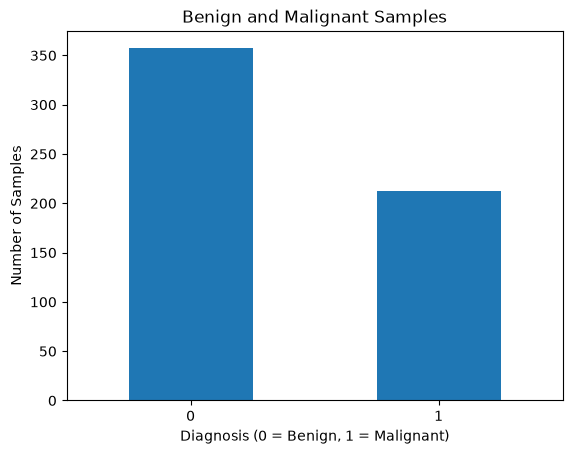

In [9]:
df["Diagnosis"].value_counts().plot(kind="bar")
plt.title("Benign and Malignant Samples")
plt.xlabel("Diagnosis (0 = Benign, 1 = Malignant)")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.show()

### In this section, we make histograms of two of the measurements. This allows us to see how the radius and texture values are spread out.

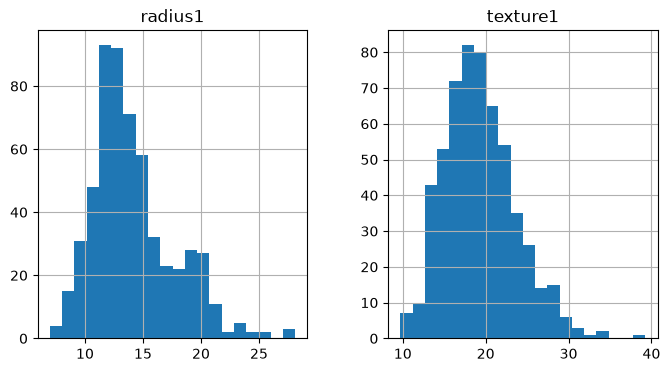

In [10]:
df[["radius1", "texture1"]].hist(bins=20, figsize=(8, 4))
plt.show()

### Here we separated the x values from the y. X contains the 30 tumor measurements and y contains the diagnosis that we want to predict.

In [11]:
X = df.drop(columns=["Diagnosis"])
y = df["Diagnosis"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (569, 30)
y shape: (569,)


### Then we split the data into training and testing sets. We use 80% of the samples to train the model and 20% to test it. The random_state makes the split the same each time we run it.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 455
Testing samples: 114


### In this section we scaled the features using StandardScaler. There are some measurements that have much larger values than others. So we fit the scaler using the training set and then apply the same scaling to the testing set.

In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("First five scaled values:", X_train_scaled[0, :5])

First five scaled values: [-1.44075296 -0.43531947 -1.36208497 -1.1391179   0.78057331]


### And in this section we created one logistic regression model and are training it using the scaled training data and then used predict() to make predictions on the test set.

In [14]:
log_reg = LogisticRegression(solver="lbfgs", max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

y_pred = log_reg.predict(X_test_scaled)

print("First 10 predictions:", y_pred[:10])
print("First 10 actual values:", y_test.values[:10])

First 10 predictions: [0 1 1 0 0 1 1 1 0 0]
First 10 actual values: [0 1 1 0 0 1 1 1 0 0]


### In this section we calcuated our accuracy of the logistic regression model

In [15]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.9736842105263158


### In this section we calcuated our precision of the logistic regression model

In [16]:
precision = precision_score(y_test, y_pred)

print("Precision:", precision)

Precision: 0.9761904761904762


### In this section we calcuated our recall of the logistic regression model

In [17]:
recall = recall_score(y_test, y_pred)

print("Recall:", recall)

Recall: 0.9534883720930233


### In this section we constructed our confusion matrix that tell us how our model performed showing us how many predictions were correct and incorrect

In [19]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[70  1]
 [ 2 41]]


### After we trained our logistic regression model, we evaluated its performance by looking at the accuracy, precision, and recall of the model. These scores show us how well our model can predict whether a tumor is benign or malignant. The confusion matrix also provided us a breakdown of correct and incorrect predictions. Overall, the results showed us that the logistic regression model was effective in determining whether a tumor would be benign or malignant based on the dataset. 